<a href="https://colab.research.google.com/github/HarshNA044/machine-learning-practice/blob/main/linear%20regression/simple_linear_regression.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# **Simple Linear Regression**

**Simple Linear Regression** is a statistical and machine learning method used to model and analyze the relationship between two continuous variables: **one independent (predictor) variable** and **one dependent (outcome) variable**. Its primary goal is to find the best-fitting straight line (known as the regression line) that predicts the dependent variable based on the independent variable.

#### **The Equation**
The mathematical formula for simple linear regression is:

$$y = \beta_{0} + \beta_{1}x + \epsilon$$

**Where:**
*   $y$: The **dependent variable** (the output or target we want to predict).
*   $x$: The **independent variable** (the input or feature used for prediction).
*   $\beta_{0}$ (Intercept): The **y-intercept**, which represents the predicted value of $y$ when $x$ is equal to zero.
*   $\beta_{1}$ (Slope): The **regression coefficient**, which indicates the direction and magnitude of the change in $y$ for every one-unit increase in $x$.
*   $\epsilon$ (Error term / Residual): The **random error or noise** that accounts for the variation in $y$ that cannot be explained by the linear relationship with $x$.

> **Objective: Predict SalesAmount using ListPrice.**
- Independent variable (X): ListPrice
- Dependent variable (y): SalesAmount


**Data sourced from [Exploratory-Data-Analysis-EDA--Retail-Sales-Data Repository](https://github.com/tejas79883/Exploratory-Data-Analysis-EDA--Retail-Sales-Data)**

**Direct CSV Link:** https://raw.githubusercontent.com/tejas79883/Exploratory-Data-Analysis-EDA--Retail-Sales-Data/main/Retail.csv

In [1]:
import pandas as pd

# **Step 1: Load dataset**

In [2]:
# importing dataset
url = "https://raw.githubusercontent.com/tejas79883/Exploratory-Data-Analysis-EDA--Retail-Sales-Data/main/Retail.csv"
data = pd.read_csv(url)

# **Step 2: Understand the dataset**

In [3]:
df=pd.DataFrame(data)

In [4]:
# first 5 rows
df.head()

,OrderNumber,ProductName,Color,Category,Subcategory,ListPrice,Orderdate,Duedate,Shipdate,PromotionName,SalesRegion,OrderQuantity,UnitPrice,SalesAmount,DiscountAmount,TaxAmount,Freight
0,SO43843,"Mountain-100 Silver, 48",Silver,Bikes,Mountain Bikes,3399.9900,1/29/2011,02-10-2011,02-05-2011,No Discount,Central,2,2039.9940,4079.9880,0.0,326.3990,101.9997
1,SO43843,"Mountain-100 Black, 48",Black,Bikes,Mountain Bikes,3374.9900,1/29/2011,02-10-2011,02-05-2011,No Discount,Central,2,2024.9940,4049.9880,0.0,323.9990,101.2497
2,SO43843,"HL Mountain Frame - Silver, 46",Silver,Components,Mountain Frames,1204.3248,1/29/2011,02-10-2011,02-05-2011,No Discount,Central,2,722.5949,1445.1898,0.0,115.6152,36.1297
3,SO43843,"Mountain-100 Black, 44",Black,Bikes,Mountain Bikes,NaN,1/29/2011,02-10-2011,02-05-2011,No Discount,Central,5,2024.9940,10124.9700,0.0,809.9976,253.1243
4,SO43843,"HL Mountain Frame - Silver, 38",Silver,Components,Mountain Frames,1204.3248,1/29/2011,02-10-2011,02-05-2011,No Discount,Central,2,722.5949,1445.1898,0.0,115.6152,36.1297


In [5]:
# size of dataframe (rows X columns)
df.shape

(32040, 17)

In [6]:
# all column names
df.columns

Index(['OrderNumber', 'ProductName', 'Color', 'Category', 'Subcategory',
       'ListPrice', 'Orderdate', 'Duedate', 'Shipdate', 'PromotionName',
       'SalesRegion', 'OrderQuantity', 'UnitPrice', 'SalesAmount',
       'DiscountAmount', 'TaxAmount', 'Freight'],
      dtype='object')

In [7]:
# provides a concise summary of a dataset, showing total rows, column names, non-missing value counts, data types, and memory usage
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 32040 entries, 0 to 32039
Data columns (total 17 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   OrderNumber     32040 non-null  object 
 1   ProductName     32040 non-null  object 
 2   Color           29073 non-null  object 
 3   Category        32040 non-null  object 
 4   Subcategory     32040 non-null  object 
 5   ListPrice       32032 non-null  float64
 6   Orderdate       32040 non-null  object 
 7   Duedate         32040 non-null  object 
 8   Shipdate        32040 non-null  object 
 9   PromotionName   32040 non-null  object 
 10  SalesRegion     32025 non-null  object 
 11  OrderQuantity   32026 non-null  object 
 12  UnitPrice       32040 non-null  float64
 13  SalesAmount     32040 non-null  float64
 14  DiscountAmount  32040 non-null  float64
 15  TaxAmount       32040 non-null  float64
 16  Freight         32040 non-null  float64
dtypes: float64(6), object(11)
memor

# **Step 3: Data Cleaning**

## Copying Dataframe
We copy a DataFrame—usually using df_cleaned = df.copy()—to protect the original raw data from accidental alterations during the cleaning and preprocessing phases.

- **Creates a Safety Net**: If you make a mistake while cleaning data (like accidentally wiping out a column or filling missing values incorrectly), you can easily revert to the original DataFrame without having to re-download or re-load the raw dataset into memory.

- **Prevents SettingWithCopyWarning**: Pandas often flags a warning when you modify a sliced portion of a DataFrame instead of an explicit copy. Creating a dedicated copy tells Pandas to create a brand new, independent object in your computer's memory, avoiding this common error.

- **Preserves the Audit Trail**: Keeping a copy allows you to compare your "before" and "after" datasets side-by-side during your Exploratory Data Analysis (EDA) to verify that your transformations worked exactly as intended.

In [8]:
df

,OrderNumber,ProductName,Color,Category,Subcategory,ListPrice,Orderdate,Duedate,Shipdate,PromotionName,SalesRegion,OrderQuantity,UnitPrice,SalesAmount,DiscountAmount,TaxAmount,Freight
0,SO43843,"Mountain-100 Silver, 48",Silver,Bikes,Mountain Bikes,3399.9900,1/29/2011,02-10-2011,02-05-2011,No Discount,Central,2,2039.9940,4079.9880,0.0,326.3990,101.9997
1,SO43843,"Mountain-100 Black, 48",Black,Bikes,Mountain Bikes,3374.9900,1/29/2011,02-10-2011,02-05-2011,No Discount,Central,2,2024.9940,4049.9880,0.0,323.9990,101.2497
2,SO43843,"HL Mountain Frame - Silver, 46",Silver,Components,Mountain Frames,1204.3248,1/29/2011,02-10-2011,02-05-2011,No Discount,Central,2,722.5949,1445.1898,0.0,115.6152,36.1297
3,SO43843,"Mountain-100 Black, 44",Black,Bikes,Mountain Bikes,NaN,1/29/2011,02-10-2011,02-05-2011,No Discount,Central,5,2024.9940,10124.9700,0.0,809.9976,253.1243
4,SO43843,"HL Mountain Frame - Silver, 38",Silver,Components,Mountain Frames,1204.3248,1/29/2011,02-10-2011,02-05-2011,No Discount,Central,2,722.5949,1445.1898,0.0,115.6152,36.1297
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
32035,SO61267,"Touring-1000 Blue, 60",Blue,Bikes,Touring Bikes,2384.0700,6/30/2013,07-12-2013,07-07-2013,No Discount,Northwest,2,1430.4420,2860.8840,0.0,228.8707,71.5221
32036,SO61267,"Touring-2000 Blue, 60",Blue,Bikes,Touring Bikes,1214.8500,6/30/2013,07-12-2013,07-07-2013,No Discount,Northwest,1,728.9100,728.9100,0.0,58.3128,18.2228
32037,SO61267,"HL Touring Frame - Blue, 60",Blue,Components,Touring Frames,1003.9100,6/30/2013,07-12-2013,07-07-2013,No Discount,Northwest,2,602.3460,1204.6920,0.0,96.3754,30.1173
32038,SO61267,"Touring-2000 Blue, 54",Blue,Bikes,Touring Bikes,1214.8500,6/30/2013,07-12-2013,07-07-2013,No Discount,Northwest,2,728.9100,1457.8200,0.0,116.6256,36.4455


In [9]:
df_cleaned = df.copy()

In [10]:
df_cleaned

,OrderNumber,ProductName,Color,Category,Subcategory,ListPrice,Orderdate,Duedate,Shipdate,PromotionName,SalesRegion,OrderQuantity,UnitPrice,SalesAmount,DiscountAmount,TaxAmount,Freight
0,SO43843,"Mountain-100 Silver, 48",Silver,Bikes,Mountain Bikes,3399.9900,1/29/2011,02-10-2011,02-05-2011,No Discount,Central,2,2039.9940,4079.9880,0.0,326.3990,101.9997
1,SO43843,"Mountain-100 Black, 48",Black,Bikes,Mountain Bikes,3374.9900,1/29/2011,02-10-2011,02-05-2011,No Discount,Central,2,2024.9940,4049.9880,0.0,323.9990,101.2497
2,SO43843,"HL Mountain Frame - Silver, 46",Silver,Components,Mountain Frames,1204.3248,1/29/2011,02-10-2011,02-05-2011,No Discount,Central,2,722.5949,1445.1898,0.0,115.6152,36.1297
3,SO43843,"Mountain-100 Black, 44",Black,Bikes,Mountain Bikes,NaN,1/29/2011,02-10-2011,02-05-2011,No Discount,Central,5,2024.9940,10124.9700,0.0,809.9976,253.1243
4,SO43843,"HL Mountain Frame - Silver, 38",Silver,Components,Mountain Frames,1204.3248,1/29/2011,02-10-2011,02-05-2011,No Discount,Central,2,722.5949,1445.1898,0.0,115.6152,36.1297
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
32035,SO61267,"Touring-1000 Blue, 60",Blue,Bikes,Touring Bikes,2384.0700,6/30/2013,07-12-2013,07-07-2013,No Discount,Northwest,2,1430.4420,2860.8840,0.0,228.8707,71.5221
32036,SO61267,"Touring-2000 Blue, 60",Blue,Bikes,Touring Bikes,1214.8500,6/30/2013,07-12-2013,07-07-2013,No Discount,Northwest,1,728.9100,728.9100,0.0,58.3128,18.2228
32037,SO61267,"HL Touring Frame - Blue, 60",Blue,Components,Touring Frames,1003.9100,6/30/2013,07-12-2013,07-07-2013,No Discount,Northwest,2,602.3460,1204.6920,0.0,96.3754,30.1173
32038,SO61267,"Touring-2000 Blue, 54",Blue,Bikes,Touring Bikes,1214.8500,6/30/2013,07-12-2013,07-07-2013,No Discount,Northwest,2,728.9100,1457.8200,0.0,116.6256,36.4455


## Removing Duplicate Rows

In [11]:
# which row is duplicated
df_cleaned.duplicated()

,0
0,False
1,False
2,False
3,False
4,False
...,...
32035,False
32036,False
32037,False
32038,False


In [12]:
# sum of all duplicated rows
df_cleaned.duplicated().sum()

# dropping duplicated rows
# df_cleaned = df_cleaned.drop_duplicates()

# in our case 0 dupicated rows are there

np.int64(0)

## Checking Missing Values

In [13]:

# counts the number of non-missing (non-null) values in each column
df_cleaned.count()

,0
OrderNumber,32040
ProductName,32040
Color,29073
Category,32040
Subcategory,32040
ListPrice,32032
Orderdate,32040
Duedate,32040
Shipdate,32040
PromotionName,32040


In [14]:
# counts total null values in each column
df_cleaned.isnull().sum()

,0
OrderNumber,0
ProductName,0
Color,2967
Category,0
Subcategory,0
ListPrice,8
Orderdate,0
Duedate,0
Shipdate,0
PromotionName,0


In [15]:
# print every unique label for all text/object columns
text_columns = df_cleaned.select_dtypes(include='object').columns

for col in text_columns:
    print("Column Name:", col)
    print("Unique Labels:", df_cleaned[col].unique(),"\n")


Column Name: OrderNumber
Unique Labels: ['SO43843' 'SO43844' 'SO43845' ... 'SO61266' 'SO61267' 'SO61268'] 

Column Name: ProductName
Unique Labels: ['Mountain-100 Silver, 48' 'Mountain-100 Black, 48'
 'HL Mountain Frame - Silver, 46' 'Mountain-100 Black, 44'
 'HL Mountain Frame - Silver, 38' 'HL Mountain Frame - Silver, 48'
 'HL Mountain Frame - Black, 48' 'Mountain-100 Silver, 38'
 'Mountain Bike Socks, M' 'Mountain-100 Black, 42'
 'Mountain-100 Black, 38' 'LL Road Frame - Red, 44'
 'Long-Sleeve Logo Jersey, L' 'Road-650 Black, 52' 'Road-650 Red, 48'
 'Road-650 Red, 62' 'Road-450 Red, 58' 'Road-650 Black, 58'
 'Road-150 Red, 56' 'LL Road Frame - Red, 60' 'AWC Logo Cap'
 'LL Road Frame - Black, 52' 'Road-450 Red, 52' 'Mountain-100 Silver, 44'
 'Long-Sleeve Logo Jersey, M' 'Sport-100 Helmet, Blue'
 'Mountain-100 Silver, 42' 'Sport-100 Helmet, Red'
 'Sport-100 Helmet, Black' 'Road-450 Red, 60' 'Road-650 Red, 44'
 'Road-450 Red, 44' 'ML Road Frame - Red, 48' 'Road-650 Red, 60'
 'Road-650 

We don't have any hidden text placeholders like '?' or 'N/A'. Our data is naturally clean in that aspect. If output shows question marks ('?'), text strings like 'N/A', or blank strings (''), then very first step is to convert them into official system nan markers through np.nan.

In data cleaning step, we only checking the missing values, but the actual handling and replacement of these missing values by actual numerical logical values will be done in later stage data preprocessing.

In [16]:
# import numpy as np
# df_cleaned = df_cleaned.replace('?',np.nan)

## Fixing Inconsistent Formats

The Orderdate column has an inconsistent format because some rows use forward slashes ('1/29/2011') while other rows use dashes ('03-01-2011')

In [17]:
df_cleaned['Orderdate'] = pd.to_datetime(df_cleaned['Orderdate'], format='mixed')
# format=mixed: rows in this column contain dates written in different formats, so read and fix each row individually

## Checking Impossible Values

The fastest way to spot impossible numbers across our entire dataset is using df.describe(). This prints a summary table showing the minimum, maximum, and average values for every numeric column.

How to spot an impossible value in the summary:
* Look closely at the min row: If it shows a negative number (e.g., -500), that is impossible.
* Look closely at the max row: If someone accidentally typed an extra zero and made a single order quantity 99999, it will stand out immediately compared to the mean.

In [18]:
df_cleaned.describe()

,ListPrice,Orderdate,UnitPrice,SalesAmount,DiscountAmount,TaxAmount,Freight
count,32032.000000,32040,32040.000000,32040.000000,32040.00000,32040.000000,32040.000000
mean,714.663419,2012-08-26 13:08:48.539325696,424.122103,1299.023131,8.15285,103.921849,32.475594
min,2.290000,2011-01-29 00:00:00,1.328200,1.374000,0.00000,0.109900,0.034400
25%,54.990000,2012-02-29 00:00:00,32.994000,125.964000,0.00000,10.077100,3.149100
50%,337.220000,2013-01-28 00:00:00,202.332000,445.410000,0.00000,35.632800,11.135300
75%,1079.990000,2013-03-30 00:00:00,647.994000,1457.820000,0.00000,116.625600,36.445500
max,3578.270000,2013-06-30 00:00:00,2146.962000,27893.619000,4005.23760,2231.489500,697.340500
std,851.623778,NaN,506.799303,2153.316625,78.40708,172.265331,53.832916


* ListPrice can't be Zero: It is the manufacturer's suggested retail price (the standard sticker price on the shelf). A store does not stock items that officially cost ₹0.00 on the shelf.
* SalesAmount can be Zero: It is the actual money collected at the cash register when a transaction occurs. A transaction total can legitimately be zero. For example, if a customer applies a 100% off coupon, wins a store giveaway, or exchanges a broken item under a warranty, they walk away paying exactly ₹0.00.

In [19]:
df_cleaned[df_cleaned['ListPrice'] <= 0]

,OrderNumber,ProductName,Color,Category,Subcategory,ListPrice,Orderdate,Duedate,Shipdate,PromotionName,SalesRegion,OrderQuantity,UnitPrice,SalesAmount,DiscountAmount,TaxAmount,Freight


In [20]:
df_cleaned[df_cleaned['SalesAmount'] < 0]

,OrderNumber,ProductName,Color,Category,Subcategory,ListPrice,Orderdate,Duedate,Shipdate,PromotionName,SalesRegion,OrderQuantity,UnitPrice,SalesAmount,DiscountAmount,TaxAmount,Freight


No impossible values present in data but if there then follow below steps.

**Note:** Our target variable is SalesAmount, so our Linear Regression model is trying to learn how to predict it. If a row has a negative or missing SalesAmount, we must delete the entire row instead of turning it into a NaN to fill later.

In [21]:
# 1. Turn 0 or negative ListPrice into NaN
# df_cleaned.loc[df_cleaned['ListPrice'] <= 0, 'ListPrice'] = np.nan

# 2. SalesAmount is our target variable: Drop rows with negative sales completely
# df_cleaned = df_cleaned[df_cleaned['SalesAmount'] >= 0]

# Verify that they are now tracked as true missing values
# print(df_cleaned[['ListPrice', 'SalesAmount']].isnull().sum())

When you want to filter specific rows and columns at the same time to change their values, we must use the .loc accessor. Without .loc, Pandas gets confused trying to read the comma inside the brackets.

## Remove records where target variable is missing

In [22]:
df_cleaned = df.dropna(subset=['SalesAmount'])

## Analysing Data

In [23]:
df_cleaned.shape

(32040, 17)

In [24]:
df_cleaned.head()

,OrderNumber,ProductName,Color,Category,Subcategory,ListPrice,Orderdate,Duedate,Shipdate,PromotionName,SalesRegion,OrderQuantity,UnitPrice,SalesAmount,DiscountAmount,TaxAmount,Freight
0,SO43843,"Mountain-100 Silver, 48",Silver,Bikes,Mountain Bikes,3399.9900,1/29/2011,02-10-2011,02-05-2011,No Discount,Central,2,2039.9940,4079.9880,0.0,326.3990,101.9997
1,SO43843,"Mountain-100 Black, 48",Black,Bikes,Mountain Bikes,3374.9900,1/29/2011,02-10-2011,02-05-2011,No Discount,Central,2,2024.9940,4049.9880,0.0,323.9990,101.2497
2,SO43843,"HL Mountain Frame - Silver, 46",Silver,Components,Mountain Frames,1204.3248,1/29/2011,02-10-2011,02-05-2011,No Discount,Central,2,722.5949,1445.1898,0.0,115.6152,36.1297
3,SO43843,"Mountain-100 Black, 44",Black,Bikes,Mountain Bikes,NaN,1/29/2011,02-10-2011,02-05-2011,No Discount,Central,5,2024.9940,10124.9700,0.0,809.9976,253.1243
4,SO43843,"HL Mountain Frame - Silver, 38",Silver,Components,Mountain Frames,1204.3248,1/29/2011,02-10-2011,02-05-2011,No Discount,Central,2,722.5949,1445.1898,0.0,115.6152,36.1297


In [25]:
# save the cleaned dataset
df_cleaned.to_csv('cleaned_dataset.csv', index=False)

# **Step 4: Data Preprocessing**

## Select require columns

In [26]:
df_simple = df[['ListPrice', 'SalesAmount']].copy()

df_simple.head()

,ListPrice,SalesAmount
0,3399.9900,4079.9880
1,3374.9900,4049.9880
2,1204.3248,1445.1898
3,NaN,10124.9700
4,1204.3248,1445.1898


## Checking missing values

In [27]:
df_simple.isnull().sum()

,0
ListPrice,8
SalesAmount,0


## Handling missing values

In [28]:
# Remove rows containing missing values
df_simple = df_simple.dropna() #dropna() removes rows where ListPrice or SalesAmount is missing

# Check missing values again
df_simple.isnull().sum()

,0
ListPrice,0
SalesAmount,0


In [29]:
# Check final dataset
df_simple.info()

<class 'pandas.core.frame.DataFrame'>
Index: 32032 entries, 0 to 32039
Data columns (total 2 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   ListPrice    32032 non-null  float64
 1   SalesAmount  32032 non-null  float64
dtypes: float64(2)
memory usage: 750.8 KB


Now our data is ready for Simple Linear Regression

# **Step 5: Exploratory Data Analysis (EDA)**

In [30]:
df_simple.describe()

,ListPrice,SalesAmount
count,32032.000000,32032.000000
mean,714.663419,1298.479509
std,851.623778,2151.398404
min,2.290000,1.374000
25%,54.990000,125.964000
50%,337.220000,445.410000
75%,1079.990000,1457.820000
max,3578.270000,27893.619000


## Handling outliers

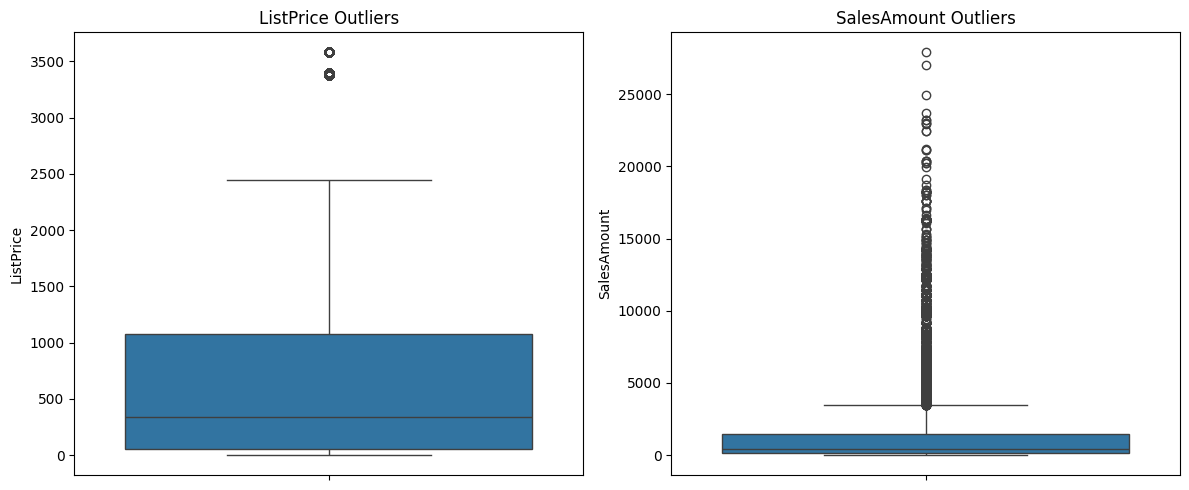

In [31]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)
sns.boxplot(y=df_simple['ListPrice'])
plt.title("ListPrice Outliers")

plt.subplot(1, 2, 2)
sns.boxplot(y=df_simple['SalesAmount'])
plt.title("SalesAmount Outliers")

plt.tight_layout()
plt.show()

In [32]:
# Calculate Q1 and Q3
Q1 = df_simple[['ListPrice', 'SalesAmount']].quantile(0.25)
Q3 = df_simple[['ListPrice', 'SalesAmount']].quantile(0.75)

# Calculate IQR
IQR = Q3 - Q1

# Calculate lower and upper limits
lower_limit = Q1 - 1.5 * IQR
upper_limit = Q3 + 1.5 * IQR

# Values below the lower limit or above the upper limit are flagged as potential outliers
print("Lower Limit:",lower_limit)
print("\nUpper Limit:",upper_limit)

Lower Limit: ListPrice     -1482.51
SalesAmount   -1871.82
dtype: float64

Upper Limit: ListPrice      2617.490
SalesAmount    3455.604
dtype: float64


In [33]:
outlier_count = (
    (df_simple[['ListPrice', 'SalesAmount']] < lower_limit) |
    (df_simple[['ListPrice', 'SalesAmount']] > upper_limit)
).sum()

print("Number of Outliers:")
print(outlier_count)

Number of Outliers:
ListPrice       846
SalesAmount    3375
dtype: int64


In [34]:
# Identify rows without outliers
df_simple_clean = df_simple[
    (
        (df_simple[['ListPrice', 'SalesAmount']] >= lower_limit) &
        (df_simple[['ListPrice', 'SalesAmount']] <= upper_limit)
    ).all(axis=1)].copy()

print("Original Shape:", df_simple.shape)
print("Shape After Removing Outliers:", df_simple_clean.shape)

Original Shape: (32032, 2)
Shape After Removing Outliers: (28459, 2)


In [35]:
outlier_count = (
    (df_simple_clean[['ListPrice', 'SalesAmount']] < lower_limit) |
    (df_simple_clean[['ListPrice', 'SalesAmount']] > upper_limit)
).sum()

print("Number of Outliers:")
print(outlier_count)

Number of Outliers:
ListPrice      0
SalesAmount    0
dtype: int64


## Check Correlation
Correlation measures the strength and direction of the relationship between numerical variables.
- +1: Perfect positive correlation.
- 0: No linear correlation.
- -1: Perfect negative correlation.

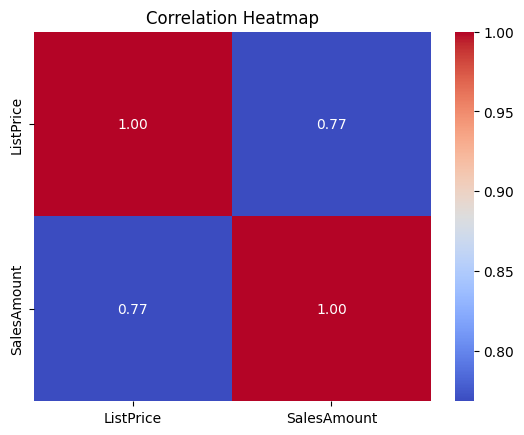

In [36]:
import matplotlib.pyplot as plt
import seaborn as sns

# visualize correlation matrix for numerical features (ListPrice and SalesAmount already numerical features)
sns.heatmap(
    df_simple_clean.corr(),
    annot=True,
    cmap='coolwarm',
    fmt='.2f'
)

plt.title("Correlation Heatmap")
plt.show()

Since correlation is 0.77 that is near to (+1), which means there is strong relation exist between ListPrice and SalesAmount in +ve direction (if one increases then other also increases and vice versa).

## Visualize ListPrice and SalesAmount

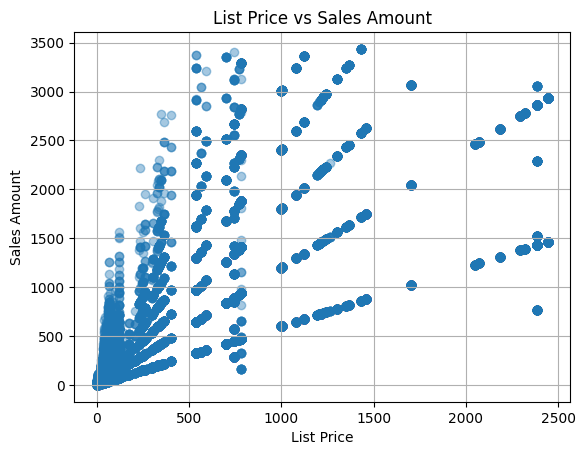

In [37]:
# alpha controls the transparency of the points in a graph. Its value ranges from 0 to 1: 0.4 = 40% (40% opacity)
# We use alpha=0.4 because our dataset contains many records (around 32,000 rows). When points overlap, transparency helps us see where observations are concentrated.
plt.scatter(
    df_simple_clean['ListPrice'],
    df_simple_clean['SalesAmount'],
    alpha=0.4
)

plt.xlabel("List Price")
plt.ylabel("Sales Amount")
plt.title("List Price vs Sales Amount")
plt.grid(True)
plt.show()

# **Step 6: Data splitting (Train-test split)**
> It is a critical data preparation technique used in machine learning to divide a single dataset into two separate, non-overlapping subsets. This ensures that the model can be evaluated fairly on data it has never seen before, preventing it from simply memorizing the answers (overfitting).

#### **The Two Main Subsets**
*   **Training Set:** The larger portion of the dataset (typically **70% to 80%**) used by the machine learning algorithm to learn patterns, fit the regression line, and optimize its parameters.
*   **Testing Set:** The remaining portion of the data (typically **20% to 30%**) held back and kept completely hidden from the model during training. It acts as an unbiased benchmark to test the model's accuracy.

#### **Why Splitting is Essential**
1. **Evaluates Generalization:** It proves whether the model can accurately make predictions on real-world, unseen data.
2. **Detects Overfitting:** If a model scores perfectly on the training data but performs poorly on the test data, it has overfit the data.
3. **Ensures Objectivity:** Evaluating a model on the same data it learned from produces a falsely optimistic performance score.



### Feature Label Separation

> Before splitting rows into train and test datasets, columns  must be separated into independent and dependent variables, known as Features (X) and the target variable or Label (y) respectively.

- X contains the independent variable used for prediction.
- y contains the dependent variable we want to predict.

In [38]:
# Independent variable
X = df_simple_clean[['ListPrice']] # Double square brackets keep X in DataFrame format.

# Dependent variable
y = df_simple_clean['SalesAmount']

print("X Shape:", X.shape)
print("y Shape:", y.shape)

X Shape: (28459, 1)
y Shape: (28459,)


In [39]:
X

,ListPrice
2,1204.3248
4,1204.3248
5,1364.5000
6,1349.6000
8,9.5000
...,...
32035,2384.0700
32036,1214.8500
32037,1003.9100
32038,1214.8500


In [40]:
y

,SalesAmount
2,1445.1898
4,1445.1898
5,818.7000
6,809.7600
8,11.4000
...,...
32035,2860.8840
32036,728.9100
32037,1204.6920
32038,1457.8200


In [41]:
# importing train test-test split function
from sklearn.model_selection import train_test_split
''' sklearn: scikit learn library
    model_selection: module
    train_test_split: function
'''

' sklearn: scikit learn library\n    model_selection: module\n    train_test_split: function\n'

In [42]:
# split the data into training and testing  parts
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

`X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)`

**What each part means:**

*   **`X, y`**: The original inputs (`X`) and targets (`y`) that we separated during feature-label separation.
*   **`test_size=0.2`**: Saves **20%** of your data for testing and uses the remaining **80%** for training.
*   **`random_state=42`**: Acts like a **"lock" for randomness**. It ensures your data is shuffled and split the exact same way every single time you run the code, making your results reproducible.
*   **`X_train, X_test, y_train, y_test`**: The four separate sets created by the function. They must be written in this **exact order** (Features first, then Labels).


In [43]:
df_simple_clean.shape

(28459, 2)

In [44]:
X_train.shape

(22767, 1)

In [45]:
X_test.shape

(5692, 1)

In [46]:
y_train.shape

(22767,)

In [47]:
y_test.shape

(5692,)

# **Step 7: Creating & Training Linear regression model**

In [48]:
# LinearRegression() creates an empty regression model. At this stage, it has not learned anything
from sklearn.linear_model import LinearRegression
model = LinearRegression()

The .fit() function trains the model.

During training, the model receives X_train and y_train.

- It identifies the relationship between input and output.

- It calculates the best-fitting regression line.

- It learns the coefficient and intercept.

The algorithm uses Ordinary Least Squares to minimize the sum of squared residuals

In [49]:
# training model
model.fit(X_train, y_train)

LinearRegression()

In [50]:
# coefficient
coefficient = model.coef_

# intercept
intercept = model.intercept_

print("Coefficient:", coefficient)
print("Intercept:", intercept)

Coefficient: [0.99106343]
Intercept: 181.52628680284897


**model.coef_:** Shows how much predicted SalesAmount changes when ListPrice increases by one unit.

**model.intercept_:** Shows predicted SalesAmount when ListPrice is zero.

# **Step 8: Making predictions using testing data**

In [51]:
# Now use the trained model to predict SalesAmount for the testing dataset
y_pred = model.predict(X_test)

# predict() takes the testing inputs and produces predicted output values using the learned regression equation

# **Step 9: Compare actual and predicted values**

In [52]:
comparison = pd.DataFrame({
    'Actual SalesAmount': y_test.values,
    'Predicted SalesAmount': y_pred
})

comparison.head(10)

,Actual SalesAmount,Predicted SalesAmount
0,136.7640,219.176786
1,65.6018,289.885594
2,149.8740,429.084020
3,2342.4546,1471.260154
4,413.0820,408.965432
5,461.6940,944.139682
6,2818.7640,957.519039
7,404.9460,255.846133
8,100.9325,214.869823
9,183.9382,485.350258


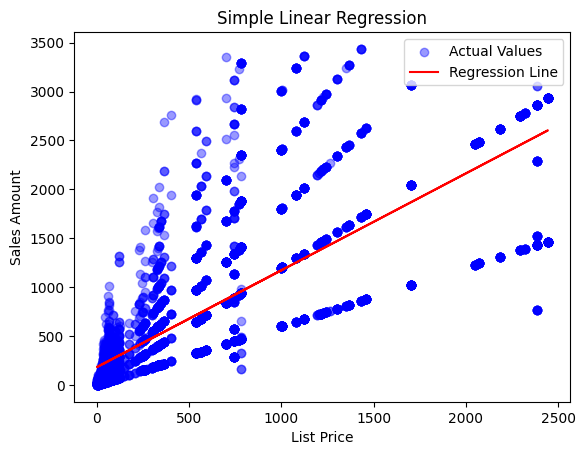

In [53]:
# regression line visualization
plt.scatter(X_test, y_test, color='blue', alpha=0.4, label='Actual Values')

plt.plot(X_test, y_pred, color='red', label='Regression Line')

plt.xlabel("List Price")
plt.ylabel("Sales Amount")
plt.title("Simple Linear Regression")

plt.legend()
plt.show()

# **Step 10: Evaluate model performance**

## Mean Squared Error (MSE)

MSE represents the average squared difference between the actual target variable and our predicted target variable

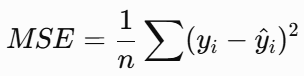

In [54]:
from sklearn.metrics import mean_squared_error, r2_score

mse = mean_squared_error(y_test, y_pred)
mse
# lower mse is better for good model

253405.20511765673

## R-squared Score (R²)

R² score (Coefficient of determination) measures the proportion of variance in the dependent variable that can be predicted by our independent variable

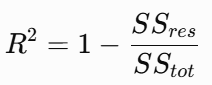

- Closer to 1: The model fits the data exceptionally well.

- Closer to 0 or negative: The model is a poor fit and does not predict the target effectively.

In [55]:
r2 = r2_score(y_test, y_pred)
r2

0.596130405853504

## K-Fold Cross-Validation

It is a robust model evaluation technique. Instead of
testing machine learning model just once on an arbitrary chunk of data,
it shuffles and splits dataset into 'K' equal parts (folds).

The model loops K times. In each loop, a different fold acts as the testing data (validation set) while the remaining folds are used for training. Finally, it
averages the scores from all K loops. This guarantees every single row of dataset gets tested, preventing misleading results.

In [56]:
from sklearn.model_selection import KFold, cross_val_score

# K = 5 is standard and safe
# shuffle=True mixes the dataset randomly before creating the K folds
kf = KFold(n_splits=5, shuffle=True, random_state=42)

# Evaluate the model using the R-squared (R^2) score metric
scores = cross_val_score(model, X_train, y_train, cv=kf, scoring="r2")

print("Scores for each of the 5 folds:", scores)
print("Final Average Accuracy Score (Average R^2):", scores.mean())

Scores for each of the 5 folds: [0.60324075 0.60261402 0.56279128 0.59176361 0.5827808 ]
Final Average Accuracy Score (Average R^2): 0.5886380907992539


We use training data for K-Fold Cross Validation because we want to evaluate how consistently the model performs during training without touching the testing data.

If we use X and y, we include the testing data in cross-validation.
This means the model-development process gets information from data that should remain untouched for final evaluation.

# **Step 11: Predict SalesAmount for a new value**

In [57]:
# New input
new_data = pd.DataFrame({
    'ListPrice': [2500]
})

# Prediction
prediction = model.predict(new_data)


print("Predicted SalesAmount:", prediction)

Predicted SalesAmount: [2659.18485127]


# **Step 12: Conclusion**
> Simple Linear Regression model achieved an MSE of 253,405.20 which indicates high prediction errors and an R² score of 0.5961 (59.61%) which means the model explains approximately 59.61% of the variation in SalesAmount using ListPrice. An MSE closer to 0 and an R² score closer to 1 indicate better performance. K fold cross validation scores were highly consistent across all folds with an overall average R² score of 0.5900 (59.00%). This high consistency across different subsets of data confirms that our simple linear regression model is reliable and generalizes well, though its predictive capability remains moderate. Overall the model has moderate performance. Since we trained it using only one feature (ListPrice), we should try Multiple Linear Regression using multiple relevant features to improve model prediction accuracy.